In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
df = pd.read_csv("AB_NYC_2019.csv")

In [15]:
df

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2


In [16]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [17]:
df.shape

(48895, 16)

In [18]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [19]:
df.isnull().sum()

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

In [20]:
df.duplicated().sum()

np.int64(0)

In [22]:
df.isnull().sum().sort_values(ascending=False)

last_review                       10052
reviews_per_month                 10052
host_name                            21
name                                 16
id                                    0
host_id                               0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
calculated_host_listings_count        0
availability_365                      0
dtype: int64

In [23]:
print("Duplicate rows:", df.duplicated().sum())
print("Column names:", df.columns.tolist())

Duplicate rows: 0
Column names: ['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']


In [24]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing = missing[missing["Missing_Count"] > 0]
display(missing.sort_values("Missing_Count", ascending=False))

,Missing_Count,Missing_Percentage
last_review,10052,20.56
reviews_per_month,10052,20.56
host_name,21,0.04
name,16,0.03


In [25]:
print("Listings with zero reviews:",
      (df["number_of_reviews"] == 0).sum())

print("Missing last_review:",
      df["last_review"].isnull().sum())

print("Missing reviews_per_month:",
      df["reviews_per_month"].isnull().sum())

print("Missing review date but positive review count:",
      (df["last_review"].isnull() &
       (df["number_of_reviews"] > 0)).sum())

Listings with zero reviews: 10052
Missing last_review: 10052
Missing reviews_per_month: 10052
Missing review date but positive review count: 0


In [26]:
print("Duplicate IDs:", df["id"].duplicated().sum())

Duplicate IDs: 0


In [27]:
# Make a copy of the original dataset
df_clean = df.copy()

# Fill missing host and listing names
df_clean["host_name"] = df_clean["host_name"].fillna("Unknown")
df_clean["name"] = df_clean["name"].fillna("Unknown")

# Fill monthly reviews with zero for listings with no reviews
df_clean.loc[
    df_clean["number_of_reviews"] == 0,
    "reviews_per_month"
] = df_clean.loc[
    df_clean["number_of_reviews"] == 0,
    "reviews_per_month"
].fillna(0)

# Convert last_review to datetime
df_clean["last_review"] = pd.to_datetime(
    df_clean["last_review"], errors="coerce"
)

print(df_clean.isnull().sum().sort_values(ascending=False))

last_review                       10052
id                                    0
name                                  0
host_id                               0
host_name                             0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
reviews_per_month                     0
calculated_host_listings_count        0
availability_365                      0
dtype: int64


In [28]:
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

print("\nRemaining missing values:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

print("\nDuplicate rows:", df_clean.duplicated().sum())
print("Duplicate IDs:", df_clean["id"].duplicated().sum())

Original shape: (48895, 16)
Cleaned shape: (48895, 16)

Remaining missing values:
last_review    10052
dtype: int64

Duplicate rows: 0
Duplicate IDs: 0


In [29]:
print(df_clean["price"].describe())

print("Zero-price listings:", (df_clean["price"] == 0).sum())
print("Negative-price listings:", (df_clean["price"] < 0).sum())

count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64
Zero-price listings: 11
Negative-price listings: 0


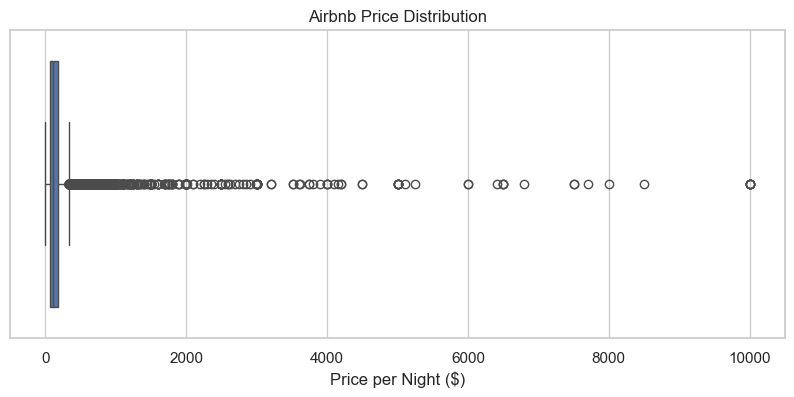

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 4))
sns.boxplot(x=df_clean["price"])
plt.title("Airbnb Price Distribution")
plt.xlabel("Price per Night ($)")
plt.show()

In [31]:
print(df_clean["price"].describe())

count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64


In [33]:
Q1 = df_clean["price"].quantile(0.25)
Q3 = df_clean["price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean["price"] < lower_bound) |
    (df_clean["price"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))

Q1: 69.0
Q3: 175.0
IQR: 106.0
Lower bound: -90.0
Upper bound: 334.0
Number of outliers: 2972


In [34]:
df_clean[
    ["name", "neighbourhood_group", "room_type", "price"]
].sort_values(
    by="price", ascending=False
).head(15)

,name,neighbourhood_group,room_type,price
9151,Furnished room in Astoria apartment,Queens,Private room,10000
17692,Luxury 1 bedroom apt. -stunning Manhattan views,Brooklyn,Entire home/apt,10000
29238,1-BR Lincoln Center,Manhattan,Entire home/apt,10000
40433,2br - The Heart of NYC: Manhattans Lower East ...,Manhattan,Entire home/apt,9999
12342,"Quiet, Clean, Lit @ LES & Chinatown",Manhattan,Private room,9999
6530,Spanish Harlem Apt,Manhattan,Entire home/apt,9999
30268,Beautiful/Spacious 1 bed luxury flat-TriBeCa/Soho,Manhattan,Entire home/apt,8500
4377,Film Location,Brooklyn,Entire home/apt,8000
29662,East 72nd Townhouse by (Hidden by Airbnb),Manhattan,Entire home/apt,7703
42523,70' Luxury MotorYacht on the Hudson,Manhattan,Entire home/apt,7500


In [36]:
print("Listings above $334:",
      (df_clean["price"] > upper_bound).sum())

print("Highest price:",
      df_clean["price"].max())

print("Zero-price listings:",
      (df_clean["price"] == 0).sum())

Listings above $334: 2972
Highest price: 10000
Zero-price listings: 11


In [38]:
df_clean[
    ["name", "neighbourhood_group", "room_type", "price"]
].sort_values(
    by="price", ascending=False
).head(15)

,name,neighbourhood_group,room_type,price
9151,Furnished room in Astoria apartment,Queens,Private room,10000
17692,Luxury 1 bedroom apt. -stunning Manhattan views,Brooklyn,Entire home/apt,10000
29238,1-BR Lincoln Center,Manhattan,Entire home/apt,10000
40433,2br - The Heart of NYC: Manhattans Lower East ...,Manhattan,Entire home/apt,9999
12342,"Quiet, Clean, Lit @ LES & Chinatown",Manhattan,Private room,9999
6530,Spanish Harlem Apt,Manhattan,Entire home/apt,9999
30268,Beautiful/Spacious 1 bed luxury flat-TriBeCa/Soho,Manhattan,Entire home/apt,8500
4377,Film Location,Brooklyn,Entire home/apt,8000
29662,East 72nd Townhouse by (Hidden by Airbnb),Manhattan,Entire home/apt,7703
42523,70' Luxury MotorYacht on the Hudson,Manhattan,Entire home/apt,7500


In [39]:
print("Highest price:", df_clean["price"].max())
print("Zero-price listings:", (df_clean["price"] == 0).sum())
print("Listings above $334:", (df_clean["price"] > 334).sum())

Highest price: 10000
Zero-price listings: 11
Listings above $334: 2972


In [40]:
df_clean.loc[
    df_clean["price"] == 0,
    ["id", "name", "neighbourhood_group", "room_type", "price"]
]

,id,name,neighbourhood_group,room_type,price
23161,18750597,"Huge Brooklyn Brownstone Living, Close to it all.",Brooklyn,Private room,0
25433,20333471,★Hostel Style Room | Ideal Traveling Buddies★,Bronx,Private room,0
25634,20523843,"MARTIAL LOFT 3: REDEMPTION (upstairs, 2nd room)",Brooklyn,Private room,0
25753,20608117,"Sunny, Quiet Room in Greenpoint",Brooklyn,Private room,0
25778,20624541,Modern apartment in the heart of Williamsburg,Brooklyn,Entire home/apt,0
25794,20639628,Spacious comfortable master bedroom with nice ...,Brooklyn,Private room,0
25795,20639792,Contemporary bedroom in brownstone with nice view,Brooklyn,Private room,0
25796,20639914,Cozy yet spacious private brownstone bedroom,Brooklyn,Private room,0
26259,20933849,the best you can find,Manhattan,Entire home/apt,0
26841,21291569,Coliving in Brooklyn! Modern design / Shared room,Brooklyn,Shared room,0


In [41]:
# Preserve df_clean; create a separate analysis dataset
df_analysis = df_clean[df_clean["price"] > 0].copy()

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Rows after excluding zero prices:", len(df_analysis))
print("Zero-price listings remaining:", (df_analysis["price"] == 0).sum())

Original rows: 48895
Cleaned rows: 48895
Rows after excluding zero prices: 48884
Zero-price listings remaining: 0


In [42]:
print("Median price before filtering:",
      df_analysis["price"].median())

df_typical = df_analysis[df_analysis["price"] <= upper_bound].copy()

print("Rows in typical-price dataset:", len(df_typical))
print("Median price after filtering:",
      df_typical["price"].median())

Median price before filtering: 106.0
Rows in typical-price dataset: 45912
Median price after filtering: 100.0


In [43]:
df_clean.loc[
    df_clean["price"] == 0,
    ["id", "name", "neighbourhood_group", "room_type", "price"]
]

,id,name,neighbourhood_group,room_type,price
23161,18750597,"Huge Brooklyn Brownstone Living, Close to it all.",Brooklyn,Private room,0
25433,20333471,★Hostel Style Room | Ideal Traveling Buddies★,Bronx,Private room,0
25634,20523843,"MARTIAL LOFT 3: REDEMPTION (upstairs, 2nd room)",Brooklyn,Private room,0
25753,20608117,"Sunny, Quiet Room in Greenpoint",Brooklyn,Private room,0
25778,20624541,Modern apartment in the heart of Williamsburg,Brooklyn,Entire home/apt,0
25794,20639628,Spacious comfortable master bedroom with nice ...,Brooklyn,Private room,0
25795,20639792,Contemporary bedroom in brownstone with nice view,Brooklyn,Private room,0
25796,20639914,Cozy yet spacious private brownstone bedroom,Brooklyn,Private room,0
26259,20933849,the best you can find,Manhattan,Entire home/apt,0
26841,21291569,Coliving in Brooklyn! Modern design / Shared room,Brooklyn,Shared room,0


In [44]:
df_analysis = df_clean[df_clean["price"] > 0].copy()

print("Rows before:", len(df_clean))
print("Rows after:", len(df_analysis))
print("Zero-price rows remaining:", (df_analysis["price"] == 0).sum())

Rows before: 48895
Rows after: 48884
Zero-price rows remaining: 0


In [45]:
# Dataset dimensions
print("Rows and columns:", df_clean.shape)

# Column names
print("\nColumns:")
print(df_clean.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df_clean.info()

# Statistical summary
display(df_clean.describe().T)


Rows and columns: (48895, 16)

Columns:
['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   id                              48895 non-null  int64         
 1   name                            48895 non-null  object        
 2   host_id                         48895 non-null  int64         
 3   host_name                       48895 non-null  object        
 4   neighbourhood_group             48895 non-null  object        
 5   neighbourhood                   48895 non-null  object        
 6   latitude                 

,count,mean,min,25%,50%,75%,max,std
id,48895.0,19017143.23618,2539.0,9471945.0,19677284.0,29152178.5,36487245.0,10983108.38561
host_id,48895.0,67620010.64661,2438.0,7822033.0,30793816.0,107434423.0,274321313.0,78610967.032667
latitude,48895.0,40.728949,40.49979,40.6901,40.72307,40.763115,40.91306,0.05453
longitude,48895.0,-73.95217,-74.24442,-73.98307,-73.95568,-73.936275,-73.71299,0.046157
price,48895.0,152.720687,0.0,69.0,106.0,175.0,10000.0,240.15417
minimum_nights,48895.0,7.029962,1.0,1.0,3.0,5.0,1250.0,20.51055
number_of_reviews,48895.0,23.274466,0.0,1.0,5.0,24.0,629.0,44.550582
last_review,38843,2018-10-04 01:47:23.910099456,2011-03-28 00:00:00,2018-07-08 00:00:00,2019-05-19 00:00:00,2019-06-23 00:00:00,2019-07-08 00:00:00,NaN
reviews_per_month,48895.0,1.09091,0.0,0.04,0.37,1.58,58.5,1.597283
calculated_host_listings_count,48895.0,7.143982,1.0,1.0,1.0,2.0,327.0,32.952519


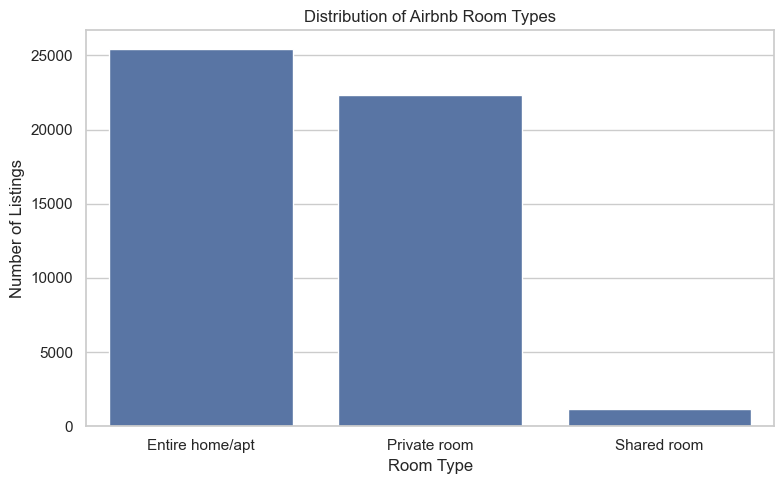

,Listing_Count
room_type,
Entire home/apt,25409
Private room,22326
Shared room,1160


In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

room_counts = df_clean["room_type"].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=room_counts.index, y=room_counts.values)
plt.title("Distribution of Airbnb Room Types")
plt.xlabel("Room Type")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

display(room_counts.to_frame("Listing_Count"))

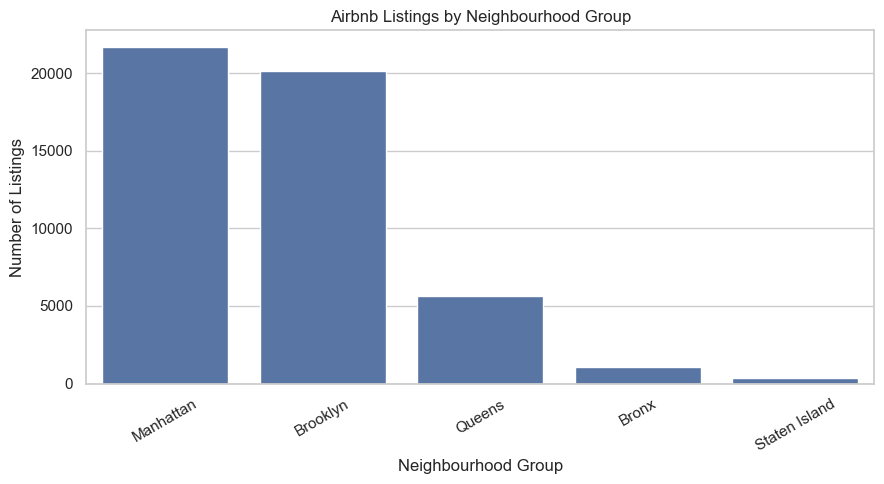

,Listing_Count
neighbourhood_group,
Manhattan,21661
Brooklyn,20104
Queens,5666
Bronx,1091
Staten Island,373


In [48]:
neighbourhood_counts = df_clean["neighbourhood_group"].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(
    x=neighbourhood_counts.index,
    y=neighbourhood_counts.values
)
plt.title("Airbnb Listings by Neighbourhood Group")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Number of Listings")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(neighbourhood_counts.to_frame("Listing_Count"))

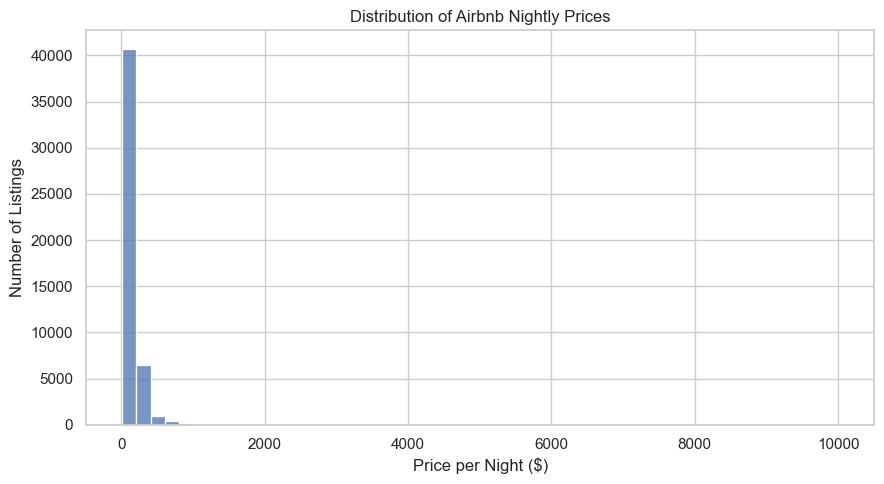

In [49]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df_analysis, x="price", bins=50)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Price per Night ($)")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

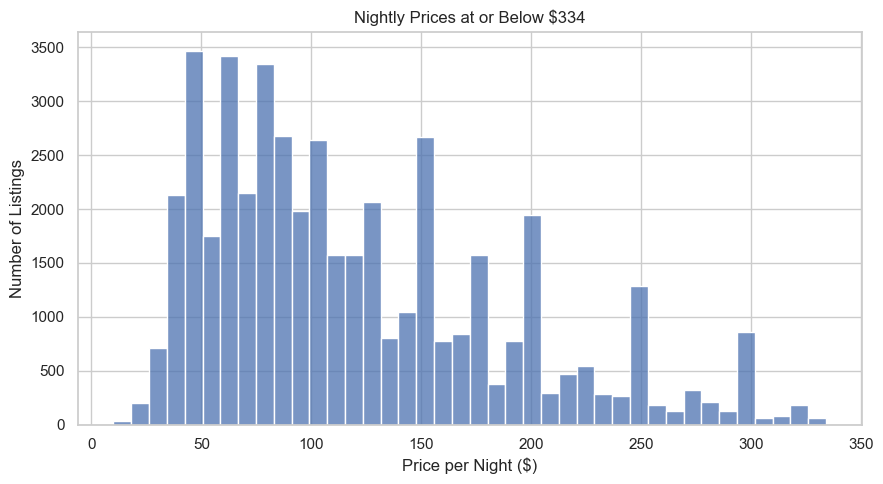

In [50]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df_analysis[df_analysis["price"] <= 334],
    x="price",
    bins=40
)
plt.title("Nightly Prices at or Below $334")
plt.xlabel("Price per Night ($)")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

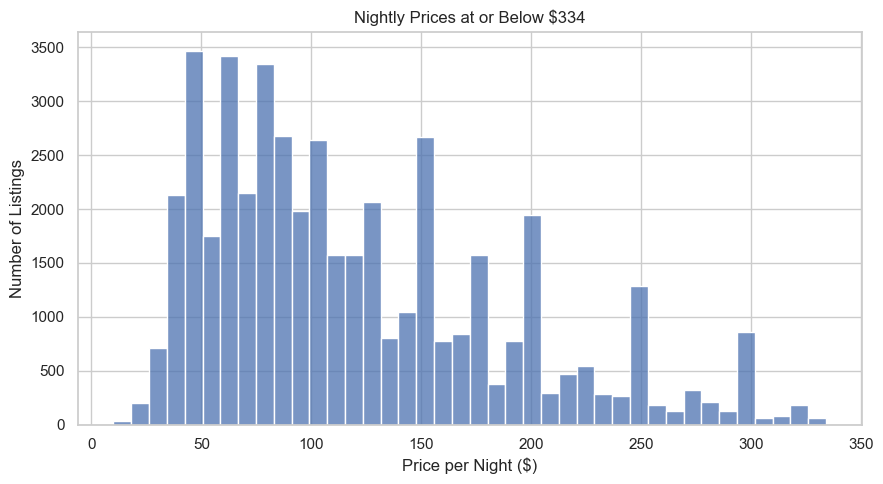

In [51]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df_analysis[df_analysis["price"] <= 334],
    x="price",
    bins=40
)
plt.title("Nightly Prices at or Below $334")
plt.xlabel("Price per Night ($)")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

In [53]:
df_clean.describe().T

,count,mean,min,25%,50%,75%,max,std
id,48895.0,19017143.23618,2539.0,9471945.0,19677284.0,29152178.5,36487245.0,10983108.38561
host_id,48895.0,67620010.64661,2438.0,7822033.0,30793816.0,107434423.0,274321313.0,78610967.032667
latitude,48895.0,40.728949,40.49979,40.6901,40.72307,40.763115,40.91306,0.05453
longitude,48895.0,-73.95217,-74.24442,-73.98307,-73.95568,-73.936275,-73.71299,0.046157
price,48895.0,152.720687,0.0,69.0,106.0,175.0,10000.0,240.15417
minimum_nights,48895.0,7.029962,1.0,1.0,3.0,5.0,1250.0,20.51055
number_of_reviews,48895.0,23.274466,0.0,1.0,5.0,24.0,629.0,44.550582
last_review,38843,2018-10-04 01:47:23.910099456,2011-03-28 00:00:00,2018-07-08 00:00:00,2019-05-19 00:00:00,2019-06-23 00:00:00,2019-07-08 00:00:00,NaN
reviews_per_month,48895.0,1.09091,0.0,0.04,0.37,1.58,58.5,1.597283
calculated_host_listings_count,48895.0,7.143982,1.0,1.0,1.0,2.0,327.0,32.952519


room_type
Entire home/apt    25409
Private room       22326
Shared room         1160
Name: count, dtype: int64


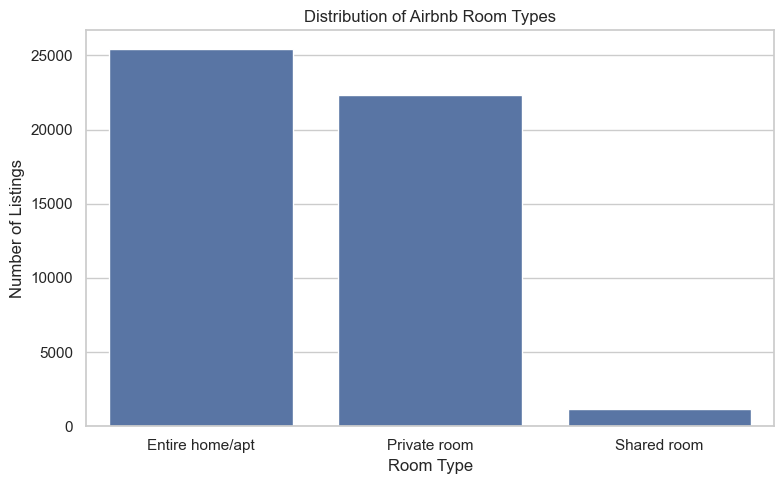

In [54]:
room_counts = df_clean["room_type"].value_counts()

print(room_counts)

plt.figure(figsize=(8, 5))
sns.barplot(x=room_counts.index, y=room_counts.values)

plt.title("Distribution of Airbnb Room Types")
plt.xlabel("Room Type")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

In [55]:
room_percentage = (
    df_clean["room_type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(room_percentage)

room_type
Entire home/apt    51.97
Private room       45.66
Shared room         2.37
Name: proportion, dtype: float64


neighbourhood_group
Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373
Name: count, dtype: int64


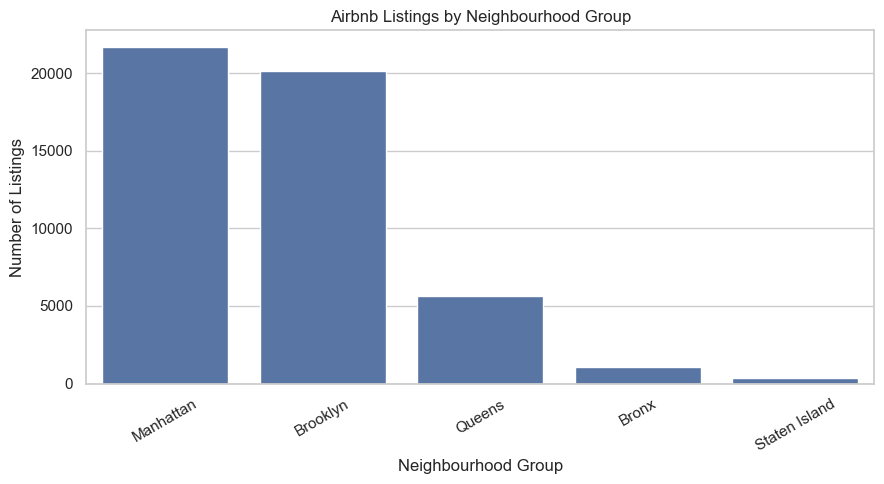

In [56]:
neighbourhood_counts = (
    df_clean["neighbourhood_group"]
    .value_counts()
)

print(neighbourhood_counts)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=neighbourhood_counts.index,
    y=neighbourhood_counts.values
)

plt.title("Airbnb Listings by Neighbourhood Group")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Number of Listings")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [57]:
borough_percentage = (
    df_clean["neighbourhood_group"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(borough_percentage)

neighbourhood_group
Manhattan        44.30
Brooklyn         41.12
Queens           11.59
Bronx             2.23
Staten Island     0.76
Name: proportion, dtype: float64


In [58]:
borough_prices = (
    df_analysis
    .groupby("neighbourhood_group")["price"]
    .agg(["count", "mean", "median"])
    .sort_values("median", ascending=False)
    .round(2)
)

display(borough_prices)

,count,mean,median
neighbourhood_group,,,
Manhattan,21660,196.88,150.0
Brooklyn,20095,124.44,90.0
Queens,5666,99.52,75.0
Staten Island,373,114.81,75.0
Bronx,1090,87.58,65.0


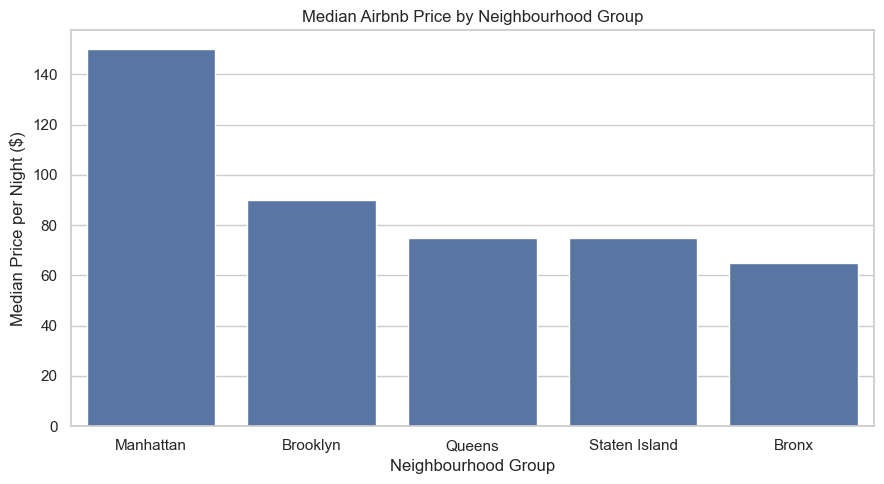

In [59]:
median_prices = borough_prices["median"].sort_values(
    ascending=False
)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=median_prices.index,
    y=median_prices.values
)

plt.title("Median Airbnb Price by Neighbourhood Group")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Median Price per Night ($)")
plt.tight_layout()
plt.show()

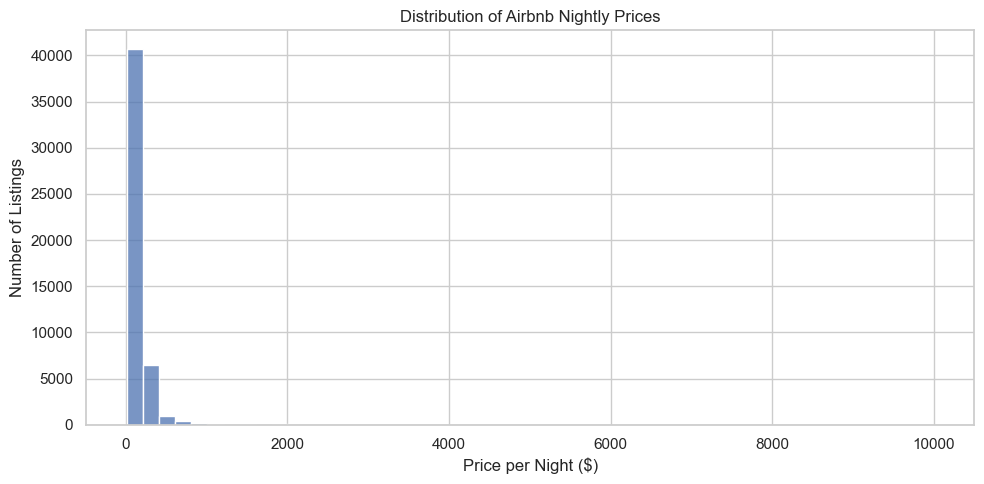

In [60]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_analysis,
    x="price",
    bins=50
)

plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Price per Night ($)")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()

In [61]:
print("Mean price:", round(df_analysis["price"].mean(), 2))
print("Median price:", df_analysis["price"].median())
print("Maximum price:", df_analysis["price"].max())

Mean price: 152.76
Median price: 106.0
Maximum price: 10000


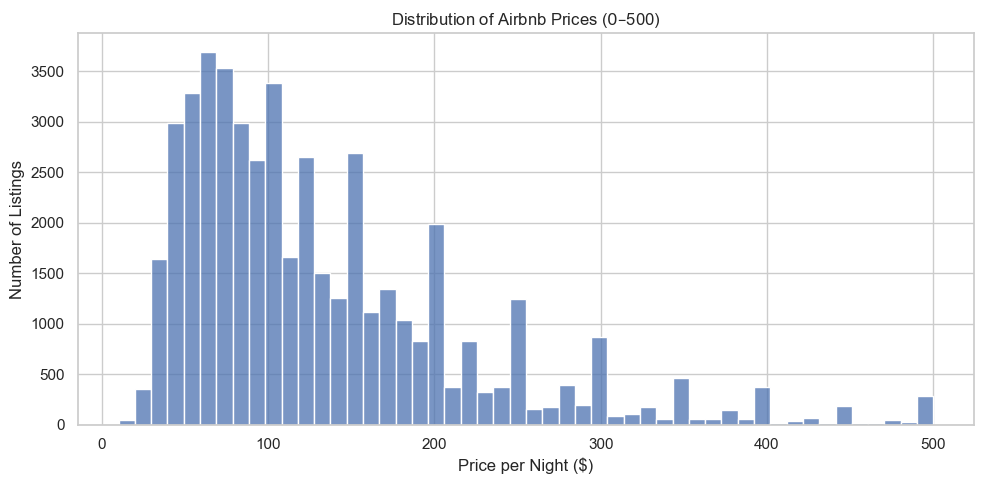

In [62]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_analysis[df_analysis["price"] <= 500],
    x="price",
    bins=50
)

plt.title("Distribution of Airbnb Prices ($0–$500)")
plt.xlabel("Price per Night ($)")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()

In [63]:
room_prices = (
    df_analysis
    .groupby("room_type")["price"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("median", ascending=False)
)

display(room_prices)

,count,mean,median
room_type,,,
Entire home/apt,25407,211.81,160.0
Private room,22319,89.81,70.0
Shared room,1158,70.25,45.0


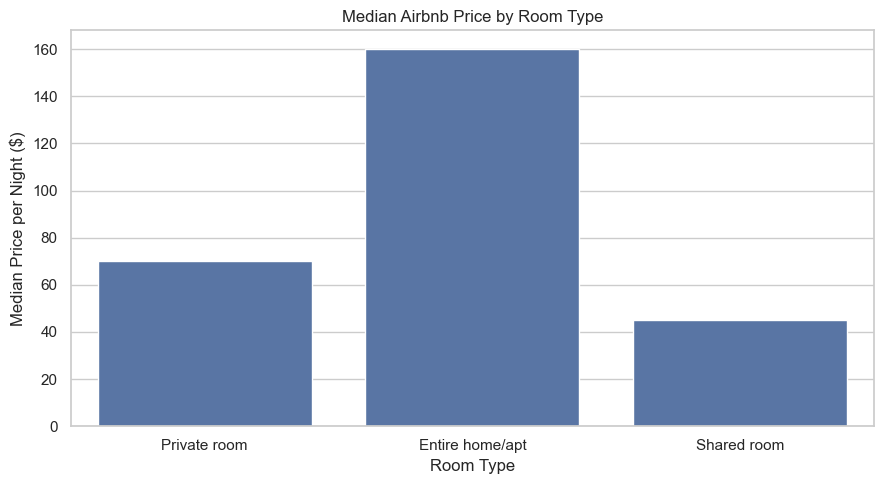

In [64]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_analysis,
    x="room_type",
    y="price",
    estimator="median",
    errorbar=None
)

plt.title("Median Airbnb Price by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Median Price per Night ($)")

plt.tight_layout()
plt.show()

In [65]:
print(df_clean["minimum_nights"].describe())

print(
    "Listings requiring more than 30 nights:",
    (df_clean["minimum_nights"] > 30).sum()
)

count    48895.000000
mean         7.029962
std         20.510550
min          1.000000
25%          1.000000
50%          3.000000
75%          5.000000
max       1250.000000
Name: minimum_nights, dtype: float64
Listings requiring more than 30 nights: 747


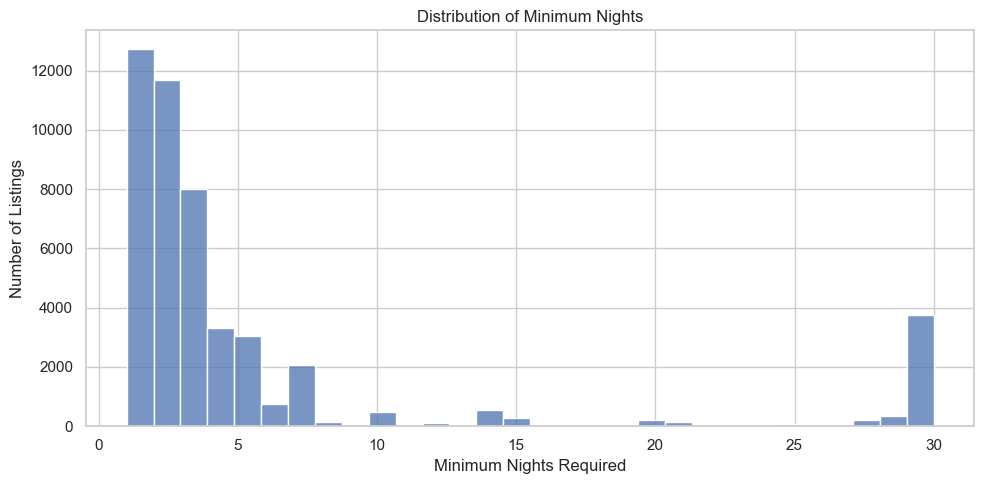

In [66]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean[df_clean["minimum_nights"] <= 30],
    x="minimum_nights",
    bins=30
)

plt.title("Distribution of Minimum Nights")
plt.xlabel("Minimum Nights Required")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()

In [67]:
print("Median minimum nights:",
      df_clean["minimum_nights"].median())

print("Listings requiring more than 30 nights:",
      (df_clean["minimum_nights"] > 30).sum())

print("Listings requiring exactly 30 nights:",
      (df_clean["minimum_nights"] == 30).sum())

print("Maximum minimum nights:",
      df_clean["minimum_nights"].max())

Median minimum nights: 3.0
Listings requiring more than 30 nights: 747
Listings requiring exactly 30 nights: 3760
Maximum minimum nights: 1250


In [68]:
top_reviewed = df_clean[
    ["name", "neighbourhood_group", "room_type", "number_of_reviews"]
].sort_values(
    by="number_of_reviews",
    ascending=False
).head(10)

display(top_reviewed)

,name,neighbourhood_group,room_type,number_of_reviews
11759,Room near JFK Queen Bed,Queens,Private room,629
2031,Great Bedroom in Manhattan,Manhattan,Private room,607
2030,Beautiful Bedroom in Manhattan,Manhattan,Private room,597
2015,Private Bedroom in Manhattan,Manhattan,Private room,594
13495,Room Near JFK Twin Beds,Queens,Private room,576
10623,Steps away from Laguardia airport,Queens,Private room,543
1879,Manhattan Lux Loft.Like.Love.Lots.Look !,Manhattan,Private room,540
20403,Cozy Room Family Home LGA Airport NO CLEANING FEE,Queens,Private room,510
4870,Private brownstone studio Brooklyn,Brooklyn,Entire home/apt,488
471,LG Private Room/Family Friendly,Brooklyn,Private room,480


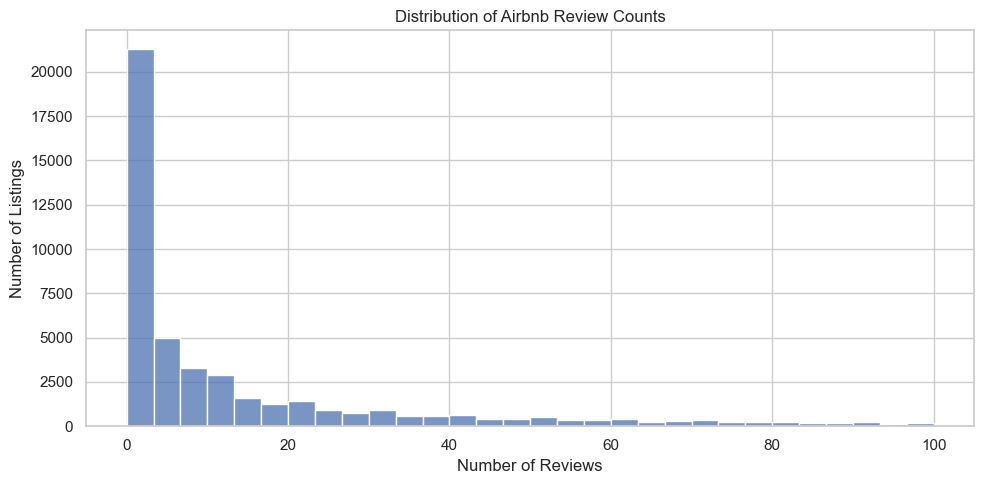

In [69]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean[df_clean["number_of_reviews"] <= 100],
    x="number_of_reviews",
    bins=30
)

plt.title("Distribution of Airbnb Review Counts")
plt.xlabel("Number of Reviews")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()

In [70]:
print("Mean reviews:",
      round(df_clean["number_of_reviews"].mean(), 2))

print("Median reviews:",
      df_clean["number_of_reviews"].median())

print("Maximum reviews:",
      df_clean["number_of_reviews"].max())

print("Listings with zero reviews:",
      (df_clean["number_of_reviews"] == 0).sum())

print("Listings with more than 100 reviews:",
      (df_clean["number_of_reviews"] > 100).sum())

Mean reviews: 23.27
Median reviews: 5.0
Maximum reviews: 629
Listings with zero reviews: 10052
Listings with more than 100 reviews: 2995


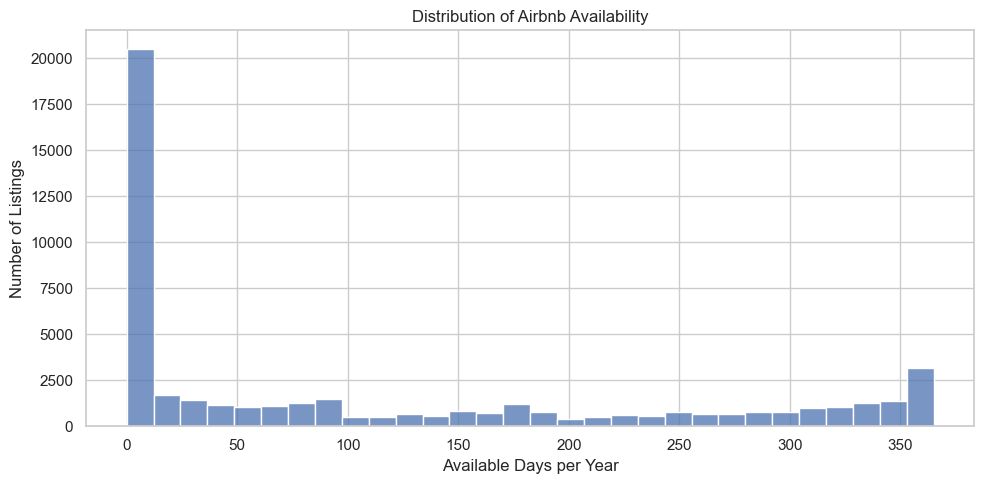

In [71]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="availability_365",
    bins=30
)

plt.title("Distribution of Airbnb Availability")
plt.xlabel("Available Days per Year")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()

In [72]:
print(df_clean["availability_365"].describe())

print(
    "Listings unavailable all year:",
    (df_clean["availability_365"] == 0).sum()
)

print(
    "Listings available all year:",
    (df_clean["availability_365"] == 365).sum()
)

count    48895.000000
mean       112.781327
std        131.622289
min          0.000000
25%          0.000000
50%         45.000000
75%        227.000000
max        365.000000
Name: availability_365, dtype: float64
Listings unavailable all year: 17533
Listings available all year: 1295


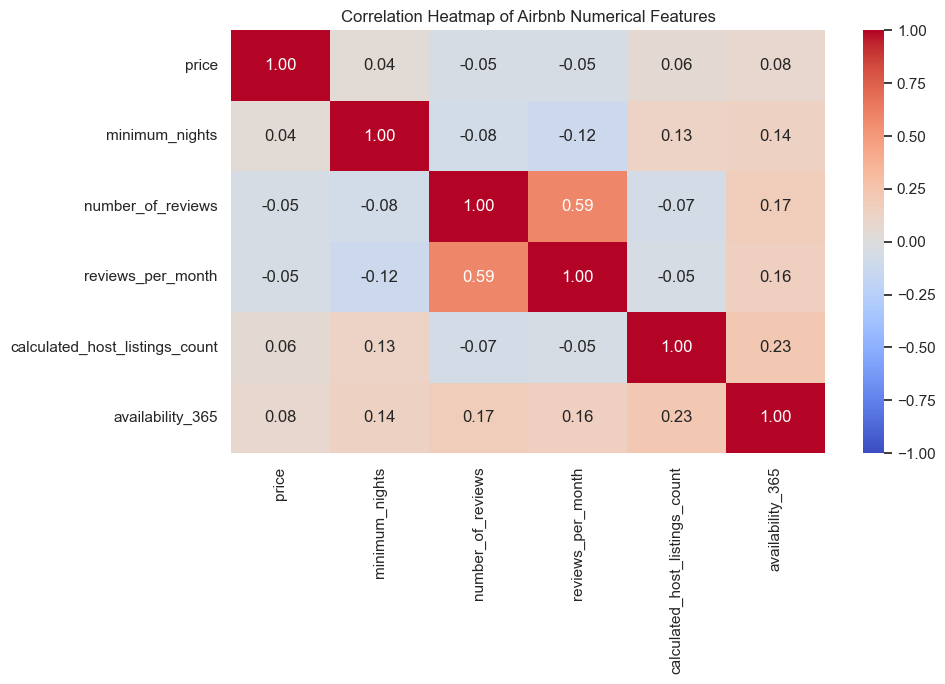

In [73]:
numeric_cols = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

corr = df_clean[numeric_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Airbnb Numerical Features")
plt.tight_layout()
plt.show()

In [74]:
summary = {
    "Total Listings": len(df_clean),
    "Unique Hosts": df_clean["host_id"].nunique(),
    "Room Types": df_clean["room_type"].nunique(),
    "Neighbourhood Groups": df_clean["neighbourhood_group"].nunique(),
    "Median Price": df_analysis["price"].median(),
    "Mean Price": round(df_analysis["price"].mean(), 2),
    "Listings With Zero Reviews": (
        df_clean["number_of_reviews"] == 0
    ).sum(),
    "Listings Unavailable All Year": (
        df_clean["availability_365"] == 0
    ).sum(),
}

display(pd.Series(summary, name="Value").to_frame())

,Value
Total Listings,48895.00
Unique Hosts,37457.00
Room Types,3.00
Neighbourhood Groups,5.00
Median Price,106.00
Mean Price,152.76
Listings With Zero Reviews,10052.00
Listings Unavailable All Year,17533.00
